In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

customers = pd.read_csv("../data/synthetic/customers.csv")
orders = pd.read_csv("../data/synthetic/orders.csv")

orders["order_date"] = pd.to_datetime(orders["order_date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

print("Churn Prediction Module Started!")

Churn Prediction Module Started!


In [2]:
# Latest available order date
latest_date = orders["order_date"].max()

# Keep 30 days for future churn labelling
snapshot_date = latest_date.normalize() - pd.Timedelta(days=30)

feature_start = snapshot_date - pd.Timedelta(days=90)
prediction_end = snapshot_date + pd.Timedelta(days=30)

print("Feature period:", feature_start, "to", snapshot_date)
print("Prediction period:", snapshot_date, "to", prediction_end)

Feature period: 2026-07-12 00:00:00 to 2026-10-10 00:00:00
Prediction period: 2026-10-10 00:00:00 to 2026-11-09 00:00:00


In [3]:
# Historical feature period
historical_orders = orders[
    (orders["order_date"] > feature_start) &
    (orders["order_date"] <= snapshot_date)
].copy()

# Delivered orders for purchase behaviour
delivered = historical_orders[
    historical_orders["order_status"] == "Delivered"
]

# Calculate customer features
features = historical_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    delayed_orders=("order_status", lambda x: (x == "Delayed").sum()),
    cancelled_orders=("order_status", lambda x: (x == "Cancelled").sum())
).reset_index()

purchase_features = delivered.groupby("customer_id").agg(
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum"),
    last_purchase=("order_date", "max"),
    average_delivery=("delivery_minutes", "mean")
).reset_index()

# Merge features
features = features.merge(
    purchase_features,
    on="customer_id",
    how="left"
)

# Include all customers who existed by the snapshot date
features = customers[
    customers["signup_date"] <= snapshot_date
][["customer_id"]].merge(
    features,
    on="customer_id",
    how="left"
)

# Fill missing values
count_columns = [
    "total_orders",
    "delayed_orders",
    "cancelled_orders",
    "frequency"
]

features[count_columns] = features[count_columns].fillna(0)

features["monetary"] = features["monetary"].fillna(0)
features["average_delivery"] = features["average_delivery"].fillna(0)

features["recency"] = (
    snapshot_date - features["last_purchase"]
).dt.days

features["recency"] = features["recency"].fillna(999)

features = features.drop(columns=["last_purchase"])

display(features.head())

,customer_id,total_orders,delayed_orders,cancelled_orders,frequency,monetary,average_delivery,recency
0,CUST0001,2.0,1.0,0.0,1.0,883.02,22.000000,53.0
1,CUST0002,2.0,0.0,0.0,2.0,373.01,27.500000,65.0
2,CUST0003,0.0,0.0,0.0,0.0,0.00,0.000000,999.0
3,CUST0004,4.0,0.0,1.0,3.0,5268.23,27.333333,11.0
4,CUST0005,4.0,0.0,0.0,4.0,10872.85,22.250000,3.0


In [4]:
future_orders = orders[
    (orders["order_date"] > snapshot_date) &
    (orders["order_date"] <= prediction_end) &
    (orders["order_status"] == "Delivered")
]

active_customer_ids = future_orders["customer_id"].unique()

features["churn"] = (
    ~features["customer_id"].isin(active_customer_ids)
).astype(int)

print("Churn target distribution:")
print(features["churn"].value_counts())

Churn target distribution:
churn
0    252
1    248
Name: count, dtype: int64


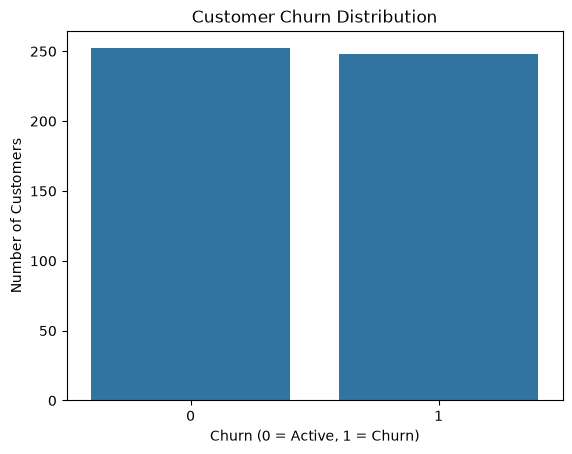

In [5]:
sns.countplot(data=features, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Active, 1 = Churn)")
plt.ylabel("Number of Customers")

plt.show()

In [6]:
print(features.shape)
print(features["churn"].value_counts())

(500, 9)
churn
0    252
1    248
Name: count, dtype: int64


In [7]:
print("Dataset shape:", features.shape)

print("\nChurn distribution:")
print(features["churn"].value_counts())

print("\nChurn percentage:")
print(
    (features["churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset shape: (500, 9)

Churn distribution:
churn
0    252
1    248
Name: count, dtype: int64

Churn percentage:
churn
0    50.4
1    49.6
Name: proportion, dtype: float64


In [8]:
print("Dataset shape:", features.shape)

print("\nChurn distribution:")
print(features["churn"].value_counts())

print("\nChurn percentage:")
print(
    (features["churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset shape: (500, 9)

Churn distribution:
churn
0    252
1    248
Name: count, dtype: int64

Churn percentage:
churn
0    50.4
1    49.6
Name: proportion, dtype: float64


In [9]:
feature_columns = [
    "total_orders",
    "delayed_orders",
    "cancelled_orders",
    "frequency",
    "monetary",
    "average_delivery",
    "recency"
]

X = features[feature_columns]
y = features["churn"]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

Input features: (500, 7)
Target: (500,)

Missing values:
total_orders        0
delayed_orders      0
cancelled_orders    0
frequency           0
monetary            0
average_delivery    0
recency             0
dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 400
Testing samples: 100


In [11]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [12]:
print(features.shape)
print(features["churn"].value_counts())

(500, 9)
churn
0    252
1    248
Name: count, dtype: int64


In [13]:
feature_columns = [
    "total_orders",
    "delayed_orders",
    "cancelled_orders",
    "frequency",
    "monetary",
    "average_delivery",
    "recency"
]

X = features[feature_columns]
y = features["churn"]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

Input features: (500, 7)
Target: (500,)

Missing values:
total_orders        0
delayed_orders      0
cancelled_orders    0
frequency           0
monetary            0
average_delivery    0
recency             0
dtype: int64


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 400
Testing samples: 100


In [15]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [16]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[1 0 0 1 1 1 1 0 0 0]

Predicted values:
[0 1 0 0 0 0 0 0 1 1]


In [17]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 55.0 %


In [18]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Active", "Churn"]
))

              precision    recall  f1-score   support

      Active       0.54      0.66      0.59        50
       Churn       0.56      0.44      0.49        50

    accuracy                           0.55       100
   macro avg       0.55      0.55      0.54       100
weighted avg       0.55      0.55      0.54       100



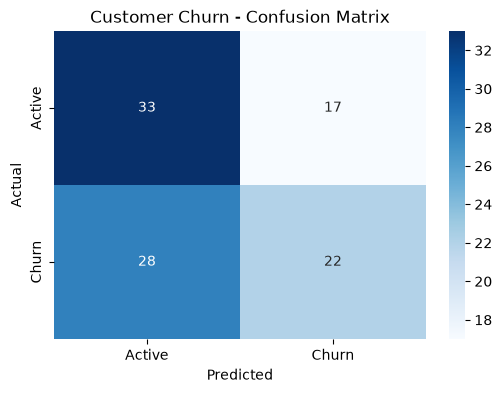

[[33 17]
 [28 22]]


In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Active", "Churn"],
    yticklabels=["Active", "Churn"]
)

plt.title("Customer Churn - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(cm)

In [20]:
y_probability = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.6696


            feature  importance
4          monetary    0.299889
6           recency    0.257679
5  average_delivery    0.232967
0      total_orders    0.086229
3         frequency    0.062332
1    delayed_orders    0.033861
2  cancelled_orders    0.027043


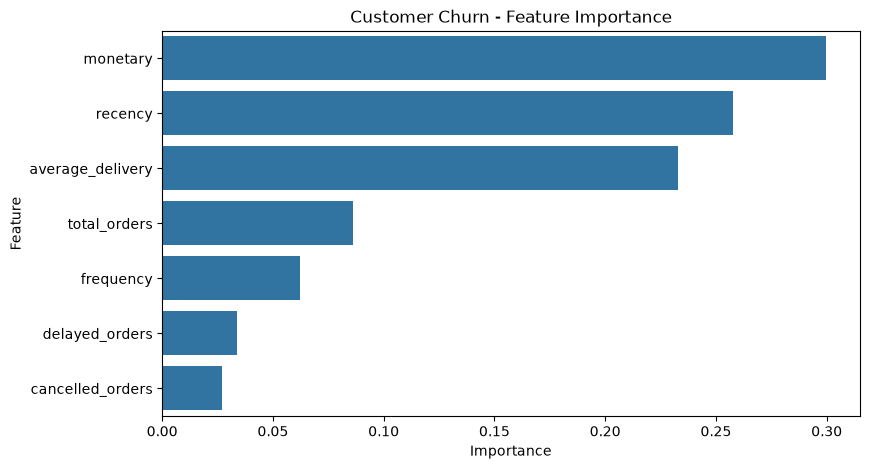

In [21]:
importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    by="importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="importance",
    y="feature"
)

plt.title("Customer Churn - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [22]:
# Predict churn probability for the test customers
churn_probability = model.predict_proba(X_test)[:, 1]

# Create customer risk report
churn_report = features.loc[X_test.index, [
    "customer_id",
    "recency",
    "frequency",
    "monetary",
    "delayed_orders",
    "cancelled_orders"
]].copy()

churn_report["churn_probability"] = churn_probability

print(churn_report.head(10))

    customer_id  recency  frequency  monetary  delayed_orders  \
169    CUST0170    999.0        0.0      0.00             0.0   
248    CUST0249     16.0        2.0   2713.82             2.0   
226    CUST0227      7.0        5.0   8276.91             0.0   
277    CUST0278     35.0        1.0    284.42             0.0   
370    CUST0371    999.0        0.0      0.00             0.0   
428    CUST0429     33.0        3.0   7800.26             0.0   
262    CUST0263      3.0        5.0   7376.75             0.0   
327    CUST0328      2.0        2.0   1187.06             1.0   
101    CUST0102     70.0        2.0   1863.83             0.0   
185    CUST0186      6.0        3.0   2239.69             0.0   

     cancelled_orders  churn_probability  
169               0.0           0.449258  
248               1.0           0.555000  
226               0.0           0.270000  
277               0.0           0.440000  
370               0.0           0.449258  
428               0.0     

In [23]:
def assign_risk(probability):
    if probability >= 0.70:
        return "High"
    elif probability >= 0.40:
        return "Medium"
    else:
        return "Low"

churn_report["risk_level"] = (
    churn_report["churn_probability"].apply(assign_risk)
)

print(churn_report[
    ["customer_id", "churn_probability", "risk_level"]
].head(15))

    customer_id  churn_probability risk_level
169    CUST0170           0.449258     Medium
248    CUST0249           0.555000     Medium
226    CUST0227           0.270000        Low
277    CUST0278           0.440000     Medium
370    CUST0371           0.449258     Medium
428    CUST0429           0.345000        Low
262    CUST0263           0.350000        Low
327    CUST0328           0.285000        Low
101    CUST0102           0.530000     Medium
185    CUST0186           0.595000     Medium
475    CUST0476           0.570000     Medium
371    CUST0372           0.445000     Medium
117    CUST0118           0.460000     Medium
244    CUST0245           0.335000        Low
80     CUST0081           0.845000       High


risk_level
Medium    48
Low       32
High      20
Name: count, dtype: int64


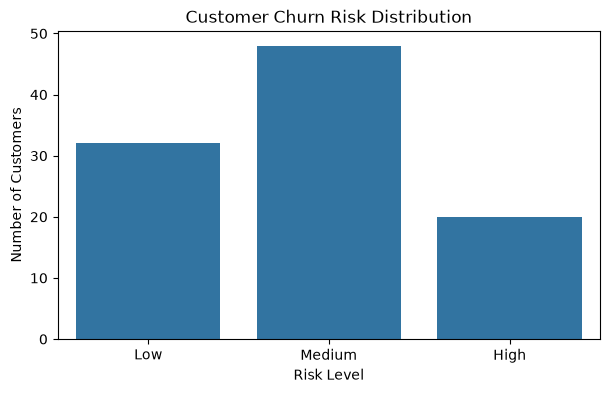

In [24]:
risk_counts = churn_report["risk_level"].value_counts()

print(risk_counts)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=churn_report,
    x="risk_level",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.show()

In [25]:
def recommend_action(row):

    if row["risk_level"] == "High":
        if row["delayed_orders"] > 0:
            return "Investigate delivery issues and offer support"
        elif row["recency"] > 30:
            return "Send personalised re-engagement offer"
        else:
            return "Prioritise customer support follow-up"

    elif row["risk_level"] == "Medium":
        if row["frequency"] <= 2:
            return "Send personalised product recommendations"
        else:
            return "Offer loyalty rewards"

    else:
        return "Maintain engagement with relevant offers"


churn_report["recommended_action"] = churn_report.apply(
    recommend_action,
    axis=1
)

print(churn_report[
    ["customer_id", "risk_level", "recommended_action"]
].head(15))

    customer_id risk_level                         recommended_action
169    CUST0170     Medium  Send personalised product recommendations
248    CUST0249     Medium  Send personalised product recommendations
226    CUST0227        Low   Maintain engagement with relevant offers
277    CUST0278     Medium  Send personalised product recommendations
370    CUST0371     Medium  Send personalised product recommendations
428    CUST0429        Low   Maintain engagement with relevant offers
262    CUST0263        Low   Maintain engagement with relevant offers
327    CUST0328        Low   Maintain engagement with relevant offers
101    CUST0102     Medium  Send personalised product recommendations
185    CUST0186     Medium                      Offer loyalty rewards
475    CUST0476     Medium  Send personalised product recommendations
371    CUST0372     Medium                      Offer loyalty rewards
117    CUST0118     Medium  Send personalised product recommendations
244    CUST0245     

In [26]:
final_report = churn_report.sort_values(
    by="churn_probability",
    ascending=False
)

print(final_report.head(20))

    customer_id  recency  frequency  monetary  delayed_orders  \
492    CUST0493    999.0        0.0      0.00             0.0   
282    CUST0283    999.0        0.0      0.00             0.0   
283    CUST0284     35.0        1.0   2072.25             0.0   
499    CUST0500     32.0        1.0   3145.56             0.0   
297    CUST0298     65.0        1.0    637.62             0.0   
80     CUST0081     24.0        1.0   1783.08             0.0   
187    CUST0188     84.0        1.0   1557.00             0.0   
272    CUST0273     64.0        1.0    539.64             0.0   
498    CUST0499     54.0        1.0   1843.52             1.0   
434    CUST0435     51.0        2.0   2626.65             0.0   
400    CUST0401     48.0        2.0   3191.18             0.0   
217    CUST0218     23.0        1.0   4775.85             0.0   
424    CUST0425     20.0        1.0   1864.33             0.0   
120    CUST0121      1.0        1.0   1610.32             0.0   
461    CUST0462     17.0 

In [27]:
final_report.to_csv(
    "../data/processed/customer_churn_risk_report.csv",
    index=False
)

print("Customer churn risk report exported successfully!")

Customer churn risk report exported successfully!
